In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))
    

/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/infer.py
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/train.py
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/evaluate.py
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/README.md
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/example_manifest.csv
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/infer_deformation.py
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/requirements.txt
/kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/DEFORMATION_README.md
/kaggle/input/datasets/swayampagare85/gameforge-lpc-ani

In [6]:
from pathlib import Path
import shutil
import sys

SOURCE = Path(
    "/kaggle/input/datasets/swayampagare85/"
    "gameforge-lpc-animation-deformation/"
    "gameforge_lpc_animation_code"
)
WORK = Path("/kaggle/working/gameforge")

assert SOURCE.exists(), f"Code folder not found: {SOURCE}"

if WORK.exists():
    shutil.rmtree(WORK)

shutil.copytree(SOURCE, WORK)

sys.path.insert(0, str(WORK))

print("Code prepared:", WORK)
print("\nFiles:")
for p in sorted(WORK.rglob("*")):
    if p.is_file():
        print(p.relative_to(WORK))

print("\nGPU:", __import__("torch").cuda.get_device_name(0))

Code prepared: /kaggle/working/gameforge

Files:
DEFORMATION_README.md
README.md
evaluate.py
example_manifest.csv
gameforge_animation/__init__.py
gameforge_animation/data.py
gameforge_animation/model.py
gameforge_deformation/__init__.py
gameforge_deformation/data.py
gameforge_deformation/model.py
infer.py
infer_deformation.py
prepare_manifest.py
requirements.txt
train.py
train_deformation.py

GPU: Tesla T4


In [7]:
from pathlib import Path

manifest = Path("/kaggle/working/gameforge/example_manifest.csv")

print(manifest.read_text()[:5000] if manifest.exists()
      else "Example manifest not found.")

print("\nAvailable dataset inputs:")
for p in Path("/kaggle/input").iterdir():
    print(p)

reference,target,split,action
# Replace this example with real verified paths; comments/placeholder rows are not valid training data.


Available dataset inputs:
/kaggle/input/datasets


In [8]:
from pathlib import Path

root = Path("/kaggle/input/datasets")
for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in {
        ".csv", ".json", ".jsonl", ".parquet", ".txt"
    }:
        print(f"\n--- {p} ({p.stat().st_size:,} bytes) ---")
        try:
            print(p.read_text(errors="replace")[:1200])
        except Exception as e:
            print("Could not read as text:", e)


--- /kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/example_manifest.csv (134 bytes) ---
reference,target,split,action
# Replace this example with real verified paths; comments/placeholder rows are not valid training data.


--- /kaggle/input/datasets/swayampagare85/gameforge-lpc-animation-deformation/gameforge_lpc_animation_code/requirements.txt (77 bytes) ---
torch>=2.2
torchvision>=0.17
Pillow>=10.0
numpy>=1.26
pandas>=2.0
tqdm>=4.66



In [9]:
from pathlib import Path

root = Path("/kaggle/working/gameforge/gameforge_deformation")

for name in ["data.py", "model.py"]:
    p = root / name
    print(f"\n{'='*20} {name} {'='*20}")
    print(p.read_text())


==================== data.py ====================
from __future__ import annotations
import json
import pandas as pd
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms.functional import pil_to_tensor


def pose_heatmaps(points, size: int, sigma: float = 2.0) -> torch.Tensor:
    """Create one Gaussian heatmap per keypoint. points are [[x,y],...] in pixel coords."""
    pts = np.asarray(points, dtype=np.float32)
    if pts.ndim != 2 or pts.shape[1] != 2:
        raise ValueError('Each keypoint field must be JSON [[x,y], ...].')
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32)
    maps = []
    for x, y in pts:
        if x < 0 or y < 0:
            maps.append(np.zeros((size, size), dtype=np.float32)); continue
        maps.append(np.exp(-((xx-x)**2 + (yy-y)**2) / (2*sigma*sigma)))
    return torch.from_numpy(np.stack(maps, axis=0))


class PairedPoseDataset(Dataset):
    """CSV columns: source_image,target_ima

In [10]:
from pathlib import Path
from collections import Counter
from PIL import Image

ROOT = Path("/kaggle/input")
extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}

counts = Counter()
samples = []

for p in ROOT.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in extensions:
        continue

    counts[str(p.parent)] += 1

    if len(samples) < 30:
        try:
            with Image.open(p) as im:
                samples.append({
                    "path": str(p),
                    "size": im.size,
                    "mode": im.mode
                })
        except Exception:
            pass

print("IMAGE COUNTS BY FOLDER:")
for folder, count in counts.most_common():
    print(f"{count:>7} images | {folder}")

print("\nSAMPLE IMAGES:")
for item in samples:
    print(item)

IMAGE COUNTS BY FOLDER:

SAMPLE IMAGES:


In [11]:
!pip install -q datasets

In [12]:
from datasets import load_dataset

action_ds = load_dataset(
    "carlosuperb/lpc-action-pixel-art-diffusion"
)

print(action_ds)
print("Columns:", action_ds["train"].column_names)
print("First sample:", action_ds["train"][0])

README.md:   0%|          | 0.00/4.20k [00:00<?, ?B/s]

images/train.zip: reconstructing file:   0%|          |  0.00B / 2.74GB            

images/train.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image'],
        num_rows: 50000
    })
})
Columns: ['image']
First sample: {'image': <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=576x768 at 0x78010D6DDD30>}


In [13]:
reference_ds = load_dataset(
    "carlosuperb/lpc-4view-pixel-art-diffusion"
)

print(reference_ds)
print("Columns:", reference_ds["train"].column_names)

README.md:   0%|          | 0.00/4.14k [00:00<?, ?B/s]

images/train.zip: reconstructing file:   0%|          |  0.00B /  278MB            

images/train.zip: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image'],
        num_rows: 50000
    })
})
Columns: ['image']


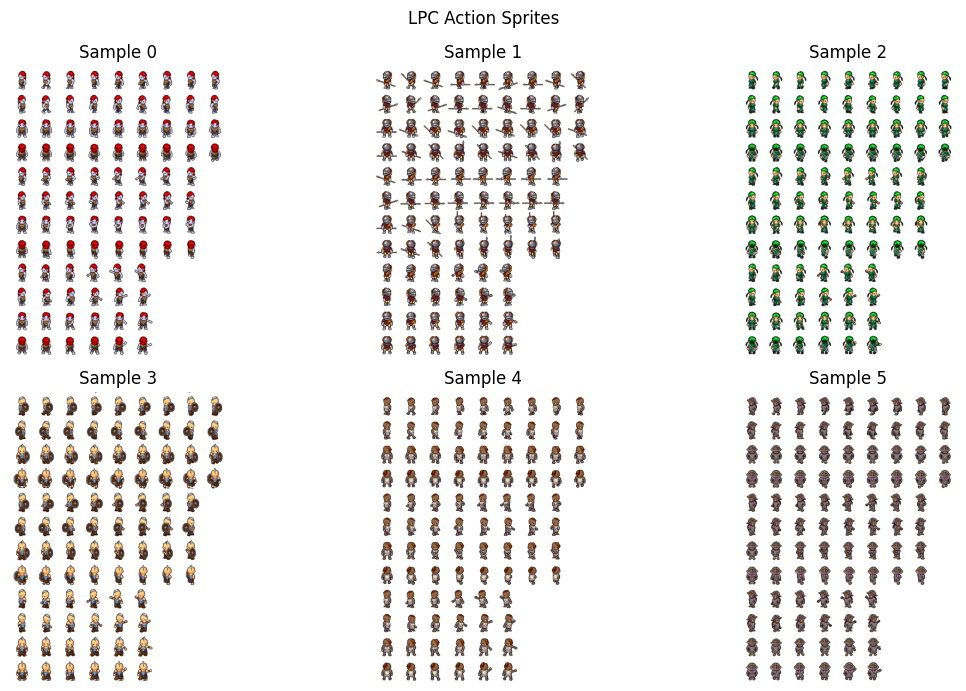

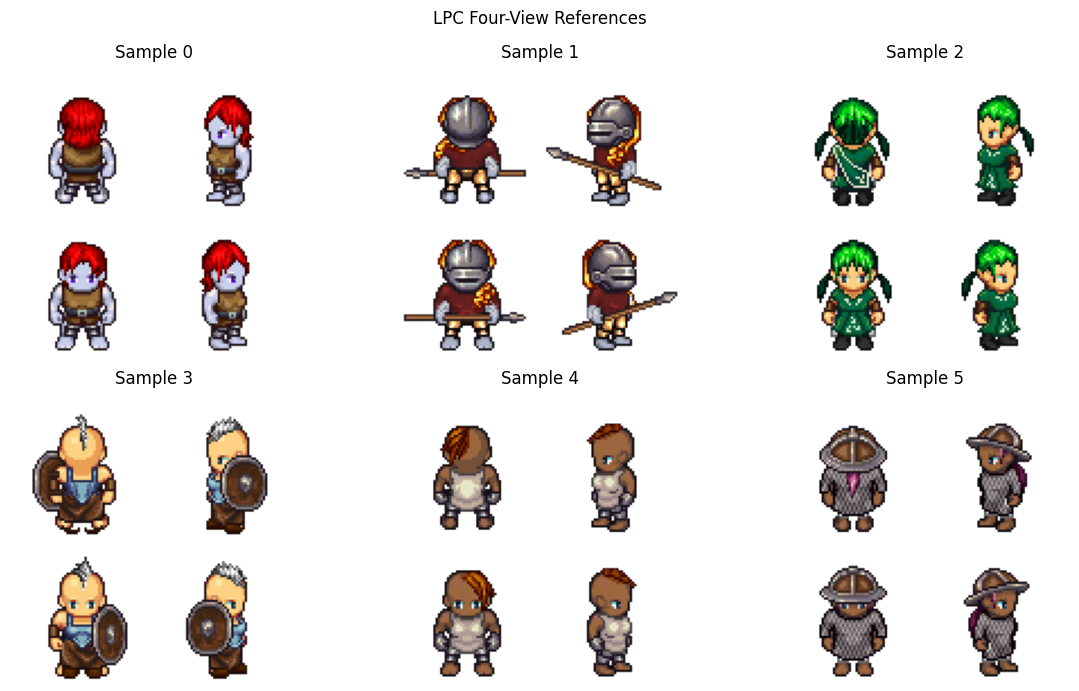

In [14]:
import matplotlib.pyplot as plt

def show_samples(ds, title, count=6):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    fig.suptitle(title)

    for i, ax in enumerate(axes.flat):
        item = ds["train"][i]["image"]
        ax.imshow(item)
        ax.set_title(f"Sample {i}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(action_ds, "LPC Action Sprites")
show_samples(reference_ds, "LPC Four-View References")